# Compact Analysis

Runs the compact benchmark comparison, then validates the saved compact strategies under actual Helstrom branch probabilities.


In [35]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Resolve paths whether the notebook is launched from the repository root or this folder.
working_directory = Path.cwd().resolve()
PROJECT_DIRECTORY = (
    working_directory / "min-error-sequential"
    if (working_directory / "min-error-sequential").is_dir()
    else working_directory
)
MODULE_DIRECTORY = PROJECT_DIRECTORY
SOURCE_DIRECTORY = PROJECT_DIRECTORY / "src"
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))

# Reload algorithm code first so comparison_analysis sees the latest heuristic signature.
import heuristic
heuristic = importlib.reload(heuristic)

# Reload local analysis code when this notebook is already open.
import comparison_analysis
comparison_analysis = importlib.reload(comparison_analysis)
field_family_summary = comparison_analysis.field_family_summary
load_paired_results = comparison_analysis.load_paired_results
overall_error_curve_summary = comparison_analysis.overall_error_curve_summary
paired_summary = comparison_analysis.paired_summary
runtime_by_k_summary = comparison_analysis.runtime_by_k_summary
run_paired_dataset = comparison_analysis.run_paired_dataset

print("Project directory:", PROJECT_DIRECTORY)
print("Source directory:", SOURCE_DIRECTORY)


Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential
Source directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/src


## Run Settings

The `RUN_SCOPE` setting selects either the balanced pilot run (`"test"`) or all compact records (`"full"`). The test scope uses 10 replicates from each field-family, $K$, and $M$ cell, giving 180 cases per dataset. The full scope uses all 2,520 cases per dimension and is much slower because every case also runs Exhaustive search.


In [36]:
# Run both spatial benchmark datasets. Each dataset contains 2,520 cases.
DATASETS = ["compact_benchmark_1d", "compact_benchmark_2d"]

# Switch here: "test" runs 180 balanced cases; "full" runs all 2,520 cases per dataset.
RUN_SCOPE = "full"
if RUN_SCOPE not in {"test", "full"}:
    raise ValueError('RUN_SCOPE must be "test" or "full"')

# None keeps every replicate; 10 gives the balanced test subset.
REPLICATES_PER_CELL = None if RUN_SCOPE == "full" else 10

PROGRESS_EVERY = 1 if RUN_SCOPE == "full" else 1

# Save result tables and figures under this directory.
RESULTS_ROOT = MODULE_DIRECTORY / "results" / "cmp_compact"

print("Run scope:", RUN_SCOPE)
print("Cases per dataset:", "2,520" if RUN_SCOPE == "full" else "180")
print("Progress interval:", PROGRESS_EVERY, "cases")
print("Results directory:", RESULTS_ROOT)


Run scope: full
Cases per dataset: 2,520
Progress interval: 1 cases
Results directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/cmp_compact


## Algorithm Configuration



In [37]:
# Exhaustive search has no optional tuning parameters.
OPTIMAL_PARAMETERS = {}

# The existing greedy method has no optional tuning parameters.
GREEDY_PARAMETERS = {}

# Configure allocation VND and final beam-tree construction.
HEURISTIC_PARAMETERS = {
    "beam_width": 3,  # Number of partial trees kept after each expansion.
    "max_iterations": 30,  # Cap VND neighborhood evaluations.
    "initialization": "near_uniform",  # Start VND from a near-uniform allocation.
    "move_sizes": (1, 2, 3),  # VND neighborhood levels: transfer L sensors.
}

# Use the same seed as the heuristic's near-uniform starting allocation.
UNIFORM_PARAMETERS = {
    "random_seed": 0,
}

# Reproduce case-specific random allocations and decision trees.
RANDOM_PARAMETERS = {
    "random_seed": 0,
}

print("Optimal parameters:", OPTIMAL_PARAMETERS)
print("Greedy parameters:", GREEDY_PARAMETERS)
print("Heuristic parameters:", HEURISTIC_PARAMETERS)
print("Uniform parameters:", UNIFORM_PARAMETERS)


Optimal parameters: {}
Greedy parameters: {}
Heuristic parameters: {'beam_width': 3, 'max_iterations': 30, 'initialization': 'near_uniform', 'move_sizes': (1, 2, 3)}
Uniform parameters: {'random_seed': 0}


## Algorithm Evaluation



In [38]:
# Keep each dimension separate so the plots can show 1D and 2D side by side.
records_by_dataset = {}
for dataset in DATASETS:
    display(Markdown(f"### Running `{dataset}`"))
    # Run all algorithms using the same cases and budgets.
    records_by_dataset[dataset] = run_paired_dataset(
        dataset,  # Name of the input benchmark directory.
        replicates_per_cell=REPLICATES_PER_CELL,  # None means all cases.
        results_root=RESULTS_ROOT,  # Base directory for comparison results.
        optimal_parameters=OPTIMAL_PARAMETERS,
        greedy_parameters=GREEDY_PARAMETERS,
        heuristic_parameters=HEURISTIC_PARAMETERS,
        uniform_parameters=UNIFORM_PARAMETERS,
        random_parameters=RANDOM_PARAMETERS,
        progress_every=PROGRESS_EVERY,
    )


### Running `compact_benchmark_1d`

compact_benchmark_1d: completed case 1/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 2/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 3/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 4/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 5/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 6/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 7/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 8/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 9/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 10/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 11/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 12/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 13/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 14/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 15/2520 (gaussian, K=3, M=3)
compact_benchmark_1

### Running `compact_benchmark_2d`

compact_benchmark_2d: completed case 1/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 2/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 3/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 4/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 5/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 6/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 7/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 8/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 9/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 10/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 11/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 12/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 13/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 14/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 15/2520 (gaussian, K=3, M=3)
compact_benchmark_2

## Paired Surrogate-Error Summary

This table compares each approximate method against the surrogate-exhaustive solution on paired runs. Error gaps are `method surrogate error - Exhaustive surrogate error`; smaller values are better. Exact-error matches count runs where the method reaches the same surrogate error as Exhaustive within the configured tolerance.


In [39]:
# Start a Markdown table for the main quality and runtime statistics.
summary_lines = [
    "| Dataset | Method | Cases | Paired runs | Mean surrogate-error gap | Maximum surrogate-error gap | Exact surrogate-error matches | Median speedup |",
    "|---|---|---:|---:|---:|---:|---:|---:|",
]
for dataset, records in records_by_dataset.items():
    # Calculate statistics from paired runs within one spatial dimension.
    summary = paired_summary(records)
    # The prefix selects the matching values from the summary dictionary.
    for method, prefix in (
        ("Greedy", "greedy"),
        ("Heuristic", "heuristic"),
        ("Uniform", "uniform"),
        ("Random", "random"),
    ):
        summary_lines.append(
            f"| {dataset} | {method} | {summary['cases']} | {summary['runs']} | "
            f"{summary[f'{prefix}_mean_gap']:.4f} | "
            f"{summary[f'{prefix}_maximum_gap']:.4f} | "
            f"{100 * summary[f'{prefix}_exact_match_rate']:.1f}% | "
            f"{summary[f'{prefix}_median_speedup']:.1f}x |"
        )
# Render the completed table inside the notebook.

display(Markdown("\n".join(summary_lines)))


| Dataset | Method | Cases | Paired runs | Mean surrogate-error gap | Maximum surrogate-error gap | Exact surrogate-error matches | Median speedup |
|---|---|---:|---:|---:|---:|---:|---:|
| compact_benchmark_1d | Greedy | 2520 | 9996 | 0.0310 | 0.2772 | 27.3% | 19.1x |
| compact_benchmark_1d | Heuristic | 2520 | 9996 | 0.0093 | 0.1658 | 50.9% | 22.3x |
| compact_benchmark_1d | Uniform | 2520 | 9996 | 0.2278 | 0.5262 | 0.5% | 157.4x |
| compact_benchmark_1d | Random | 2520 | 9996 | 0.1914 | 0.6901 | 0.4% | 154.4x |
| compact_benchmark_2d | Greedy | 2520 | 10019 | 0.0301 | 0.3178 | 29.2% | 19.1x |
| compact_benchmark_2d | Heuristic | 2520 | 10019 | 0.0102 | 0.1927 | 49.2% | 22.7x |
| compact_benchmark_2d | Uniform | 2520 | 10019 | 0.2283 | 0.5891 | 0.4% | 160.1x |
| compact_benchmark_2d | Random | 2520 | 10019 | 0.1981 | 0.6309 | 0.4% | 158.4x |

## Overall Surrogate-Error Curve Summary

Each row is one point in the overall mean-error curves. The error columns are surrogate final errors from the fixed decision trees. Gap cells show absolute error reductions and percentage reductions; positive values mean the second method is better.


In [40]:
curve_summary_lines = [
    r"| Dimension | Budget level | Mean $N/N_{\min}^{opt}$ | Optimal mean surrogate error | Greedy mean surrogate error | Heuristic mean surrogate error | Uniform mean surrogate error | Random mean surrogate error | Optimal reduction from Greedy | Optimal reduction from Heuristic | Heuristic reduction from Greedy |",
    "|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in overall_error_curve_summary(records):
        curve_summary_lines.append(
            f"| {row['dimension']} | {row['budget_level']} | "
            f"{row['mean_budget_fraction']:.3f} | "
            f"{row['optimal_mean_error']:.4f} | "
            f"{row['greedy_mean_error']:.4f} | "
            f"{row['heuristic_mean_error']:.4f} | "
            f"{row['uniform_mean_error']:.4f} | "
            f"{row['random_mean_error']:.4f} | "
            f"{row['optimal_from_greedy']:.4f} "
            f"({row['optimal_from_greedy_percent']:.1f}%) | "
            f"{row['optimal_from_heuristic']:.4f} "
            f"({row['optimal_from_heuristic_percent']:.1f}%) | "
            f"{row['heuristic_from_greedy']:.4f} "
            f"({row['heuristic_from_greedy_percent']:.1f}%) |"
        )

display(Markdown("\n".join(curve_summary_lines)))


| Dimension | Budget level | Mean $N/N_{\min}^{opt}$ | Optimal mean surrogate error | Greedy mean surrogate error | Heuristic mean surrogate error | Uniform mean surrogate error | Random mean surrogate error | Optimal reduction from Greedy | Optimal reduction from Heuristic | Heuristic reduction from Greedy |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 1D | 1 | 0.180 | 0.2951 | 0.3317 | 0.3034 | 0.5407 | 0.4894 | 0.0366 (11.0%) | 0.0083 (2.7%) | 0.0283 (8.5%) |
| 1D | 2 | 0.337 | 0.1393 | 0.1705 | 0.1517 | 0.4049 | 0.3579 | 0.0312 (18.3%) | 0.0125 (8.2%) | 0.0187 (11.0%) |
| 1D | 3 | 0.502 | 0.0708 | 0.1001 | 0.0808 | 0.2906 | 0.2606 | 0.0293 (29.2%) | 0.0099 (12.3%) | 0.0194 (19.3%) |
| 1D | 4 | 0.639 | 0.0425 | 0.0694 | 0.0491 | 0.2214 | 0.2047 | 0.0269 (38.7%) | 0.0065 (13.3%) | 0.0203 (29.3%) |
| 2D | 1 | 0.165 | 0.3365 | 0.3702 | 0.3443 | 0.5611 | 0.5204 | 0.0338 (9.1%) | 0.0078 (2.3%) | 0.0259 (7.0%) |
| 2D | 2 | 0.308 | 0.1761 | 0.2060 | 0.1892 | 0.4394 | 0.3988 | 0.0299 (14.5%) | 0.0130 (6.9%) | 0.0168 (8.2%) |
| 2D | 3 | 0.460 | 0.0997 | 0.1287 | 0.1110 | 0.3305 | 0.3059 | 0.0290 (22.5%) | 0.0113 (10.2%) | 0.0177 (13.8%) |
| 2D | 4 | 0.585 | 0.0655 | 0.0934 | 0.0741 | 0.2591 | 0.2448 | 0.0279 (29.8%) | 0.0086 (11.6%) | 0.0192 (20.6%) |

## Runtime Summary by Number of Fields



In [41]:
runtime_summary_lines = [
    "| Dimension | $K$ | Optimal median runtime (s) | Greedy runtime (speedup) | Heuristic runtime (speedup) | Uniform runtime (speedup) | Random runtime (speedup) |",
    "|---|---:|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in runtime_by_k_summary(records):
        runtime_summary_lines.append(
            f"| {row['dimension']} | {row['K']} | "
            f"{row['optimal_median_seconds']:.6f} | "
            f"{row['greedy_median_seconds']:.6f} "
            f"({row['greedy_median_speedup']:.1f}x) | "
            f"{row['heuristic_median_seconds']:.6f} "
            f"({row['heuristic_median_speedup']:.1f}x) | "
            f"{row['uniform_median_seconds']:.6f} "
            f"({row['uniform_median_speedup']:.1f}x) | "
            f"{row['random_median_seconds']:.6f} "
            f"({row['random_median_speedup']:.1f}x) |"
        )

display(Markdown("\n".join(runtime_summary_lines)))


| Dimension | $K$ | Optimal median runtime (s) | Greedy runtime (speedup) | Heuristic runtime (speedup) | Uniform runtime (speedup) | Random runtime (speedup) |
|---|---:|---:|---:|---:|---:|---:|
| 1D | 3 | 0.001585 | 0.000446 (3.0x) | 0.000437 (3.4x) | 0.000091 (16.2x) | 0.000091 (15.8x) |
| 1D | 4 | 0.027274 | 0.001299 (19.0x) | 0.001364 (21.3x) | 0.000219 (150.2x) | 0.000223 (147.8x) |
| 1D | 5 | 0.584356 | 0.002589 (196.0x) | 0.003700 (178.8x) | 0.000373 (1873.5x) | 0.000379 (1844.8x) |
| 2D | 3 | 0.000875 | 0.000301 (3.1x) | 0.000282 (3.5x) | 0.000059 (16.9x) | 0.000061 (16.6x) |
| 2D | 4 | 0.017665 | 0.000762 (19.1x) | 0.000752 (22.3x) | 0.000113 (156.3x) | 0.000114 (155.0x) |
| 2D | 5 | 0.360521 | 0.001804 (195.5x) | 0.002033 (178.8x) | 0.000193 (1887.0x) | 0.000194 (1872.5x) |

## Error-Gap Summary by Field Family



In [42]:
family_summary_lines = [
    "| Dimension | Field family | Greedy mean surrogate-error gap | Heuristic mean surrogate-error gap | Uniform mean surrogate-error gap | Random mean surrogate-error gap | Heuristic gap reduction from Greedy |",
    "|---|---|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in field_family_summary(records):
        family_summary_lines.append(
            f"| {row['dimension']} | {row['field_family']} | "
            f"{row['greedy_mean_gap']:.4f} | "
            f"{row['heuristic_mean_gap']:.4f} | "
            f"{row['uniform_mean_gap']:.4f} | "
            f"{row['random_mean_gap']:.4f} | "
            f"{row['heuristic_gap_reduction']:.4f} "
            f"({row['heuristic_gap_reduction_percent']:.1f}%) |"
        )

display(Markdown("\n".join(family_summary_lines)))


| Dimension | Field family | Greedy mean surrogate-error gap | Heuristic mean surrogate-error gap | Uniform mean surrogate-error gap | Random mean surrogate-error gap | Heuristic gap reduction from Greedy |
|---|---|---:|---:|---:|---:|---:|
| 1D | gaussian | 0.0328 | 0.0089 | 0.2286 | 0.2023 | 0.0238 (72.8%) |
| 1D | sinusoidal | 0.0239 | 0.0052 | 0.1740 | 0.1523 | 0.0187 (78.2%) |
| 1D | quadratic | 0.0362 | 0.0137 | 0.2794 | 0.2186 | 0.0225 (62.1%) |
| 2D | gaussian | 0.0329 | 0.0098 | 0.2296 | 0.2183 | 0.0231 (70.2%) |
| 2D | sinusoidal | 0.0214 | 0.0050 | 0.1708 | 0.1531 | 0.0164 (76.6%) |
| 2D | quadratic | 0.0359 | 0.0157 | 0.2834 | 0.2221 | 0.0202 (56.3%) |

## Comparison Plots

These figures use surrogate final error, because this notebook compares algorithms under the objective used for optimization.

1. **Mean surrogate-error curves:** quality-budget tradeoff separately for each $K$.
2. **Overall mean surrogate-error curves:** 1D and 2D summaries averaged across all included $K$, $M$, and field families.
3. **Runtime speedup:** computational benefit relative to exhaustive search.
4. **Surrogate-error gap by field family:** Gaussian, sinusoidal, and quadratic fields.


## Mean surrogate-error curves

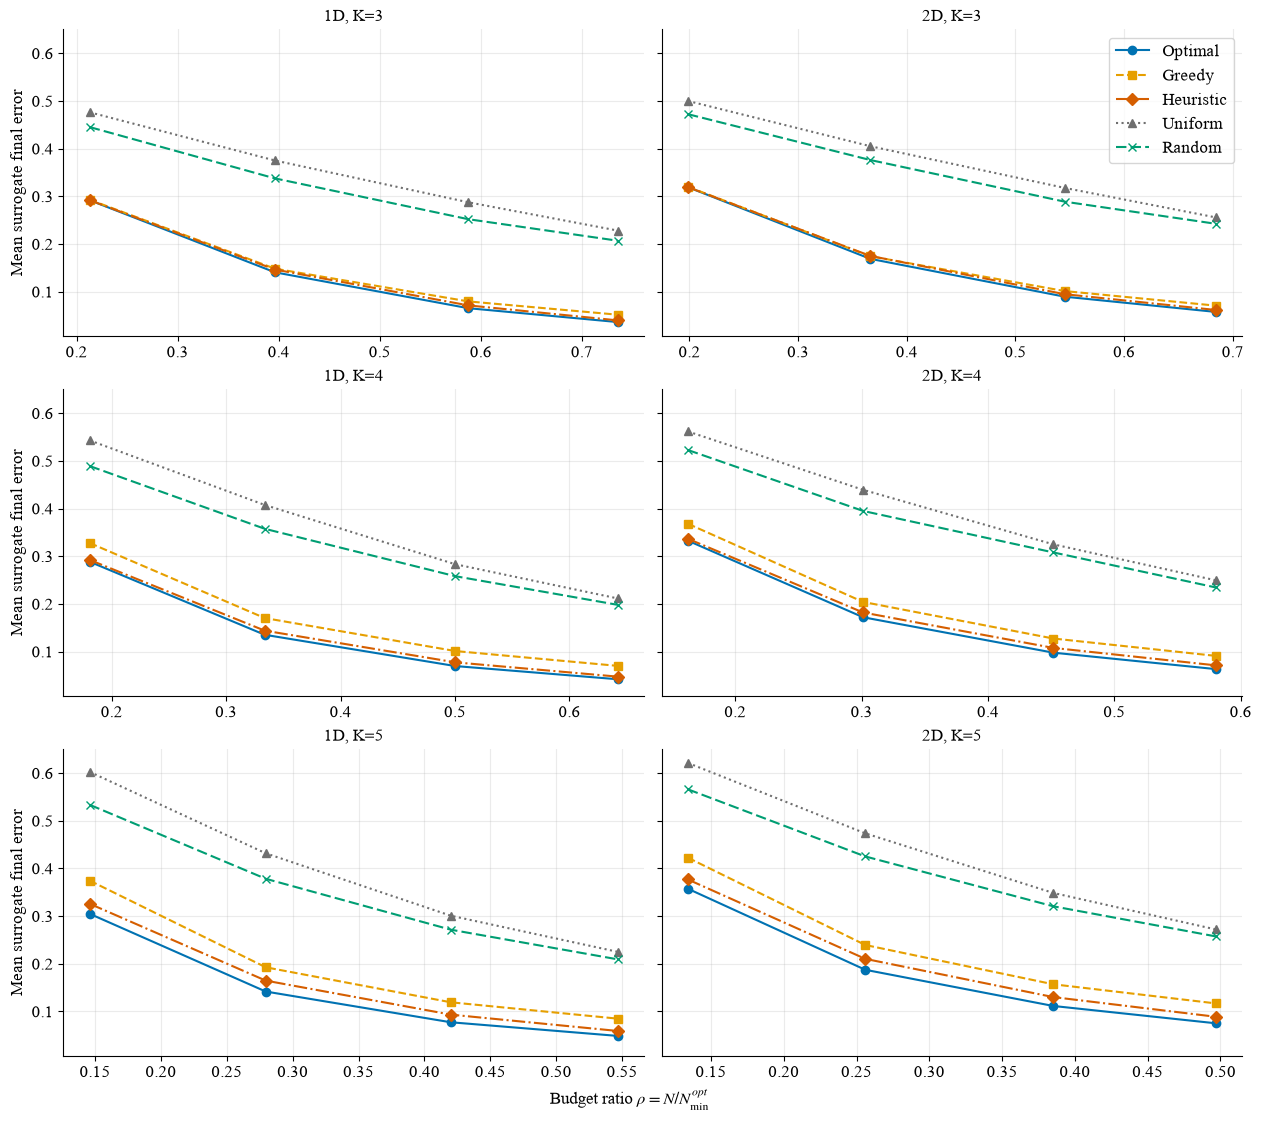

## Overall mean surrogate-error curves

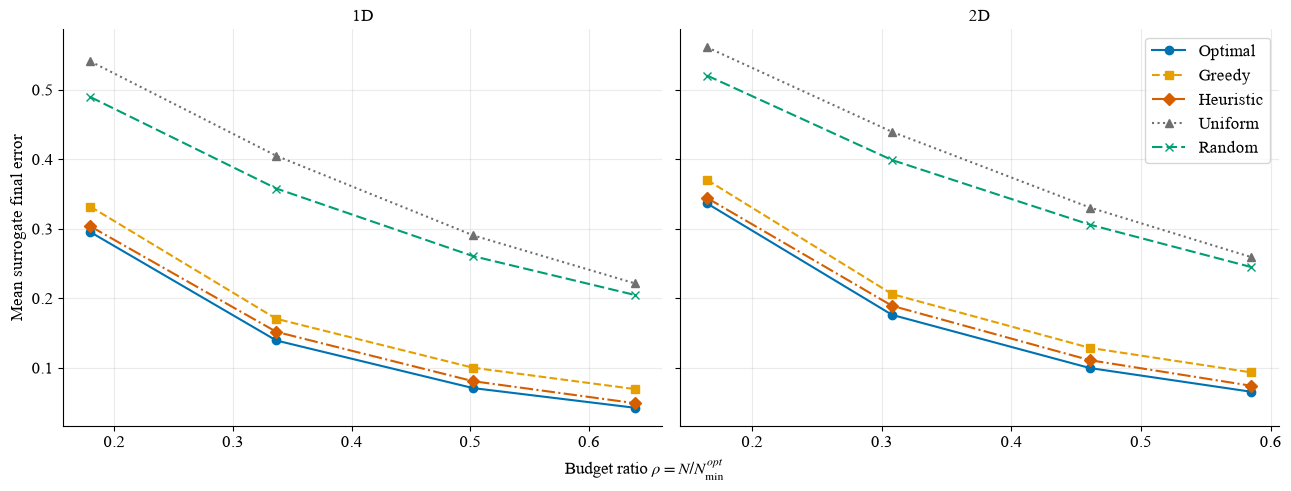

## Runtime speedup

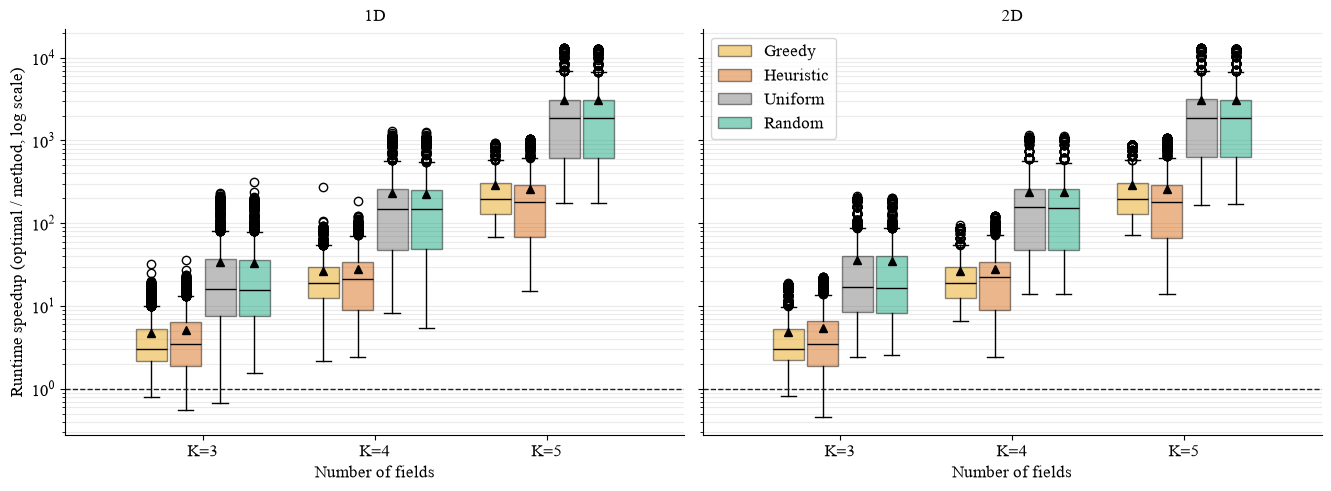

## Surrogate-error gap by field family

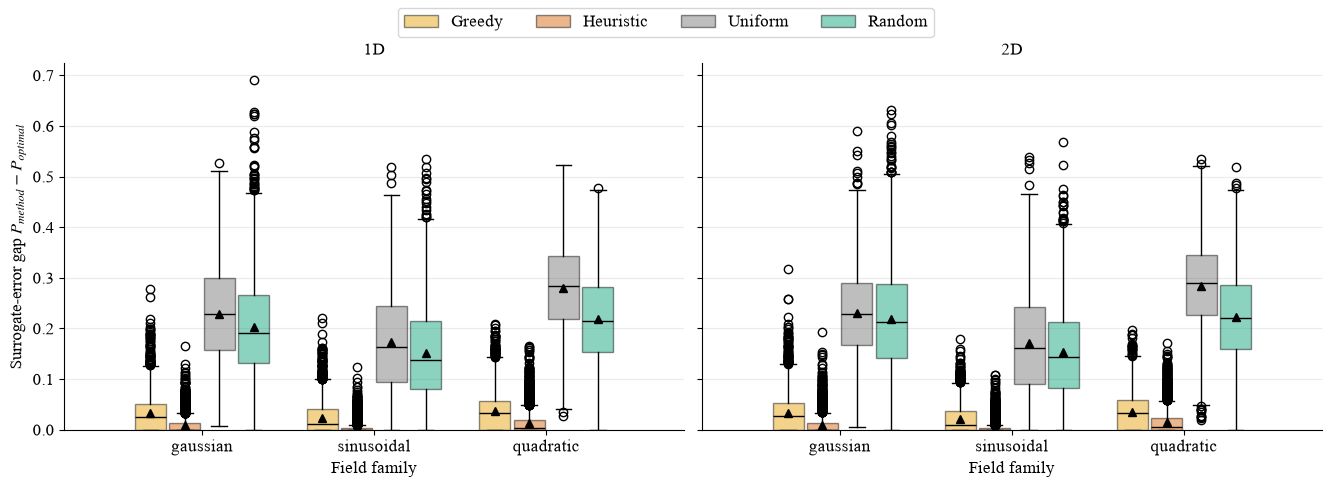

In [43]:
# Close old figures, then reload and apply the shared style.
plt.close("all")
import plot_style
plot_style = importlib.reload(plot_style)
plot_style.configure_plot_style()
# Reload plotting code so an open kernel does not reuse older functions.
comparison_analysis = importlib.reload(comparison_analysis)
# Load saved records when the expensive run cell was intentionally skipped.
if "records_by_dataset" not in globals():
    records_by_dataset = {
        dataset: comparison_analysis.load_paired_results(
            dataset, results_root=RESULTS_ROOT, run_scope=RUN_SCOPE
        )
        for dataset in DATASETS
    }
# Create the four selected figures and save PNG and PDF copies.
for title, figure in comparison_analysis.make_combined_comparison_plots(
    records_by_dataset,  # Paired results for both dimensions.
    results_root=RESULTS_ROOT,  # Base directory for comparison results.
    run_scope=RUN_SCOPE,  # Keeps test and full-run summaries separate.
):
    display(Markdown(f"## {title}"))
    display(figure)
    plt.close(figure)


## Saved Files

The notebook saves detailed tables separately by dimension and puts the side-by-side figures in one combined folder:

```text
results/cmp_compact/
├── compact_1d_<test|full>/tables/
├── compact_2d_<test|full>/tables/
└── summary_compact_1d_compact_2d_<test|full>/figures/
    ├── mean_error_curves.*
    ├── runtime_speedup.*
    └── error_gap_by_field_family.*
```



## Actual-Error Validation

This section uses the compact comparison results saved above and reevaluates the fixed allocations and trees using actual branch probabilities.


In [44]:
import json
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Resolve paths whether the notebook is launched from the repository root or this folder.
working_directory = Path.cwd().resolve()
project_directory = (
    working_directory / "min-error-sequential"
    if (working_directory / "min-error-sequential").is_dir()
    else working_directory
)
source_directory = project_directory / "src"
if str(source_directory) not in sys.path:
    sys.path.insert(0, str(source_directory))

# Reload algorithm modules before reloading the analysis wrapper.
import heuristic
heuristic = importlib.reload(heuristic)

import actual_error_analysis
actual_error_analysis = importlib.reload(actual_error_analysis)

run_actual_error = actual_error_analysis.run_actual_error_evaluation
actual_error_summary = actual_error_analysis.actual_error_summary
actual_method_comparison_summary = actual_error_analysis.actual_method_comparison_summary
surrogate_quality_summary = actual_error_analysis.surrogate_quality_summary
bias_mae_summary = actual_error_analysis.bias_mae_summary
within_budget_correlation_summary = actual_error_analysis.within_budget_correlation_summary
method_ranking_agreement_summary = actual_error_analysis.method_ranking_agreement_summary
residual_by_k_summary = actual_error_analysis.residual_by_k_summary

print("Project directory:", project_directory)
print("Source directory:", source_directory)
print("Using actual_error_analysis from:", actual_error_analysis.__file__)


Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential
Source directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/src
Using actual_error_analysis from: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/src/actual_error_analysis.py


## Settings

The `COMPACT_RUN_SCOPE` setting selects either saved compact pilot records (`"test"`) or saved full compact records (`"full"`). This notebook is compact-only and includes Exhaustive, Greedy, Allocation + tree heuristic, Uniform, and Random because those strategies are saved by the compact comparison pipeline.



In [45]:
# Compact data: includes Exhaustive, Greedy, Allocation + tree heuristic, Uniform, and Random.
COMPACT_DATASETS = ("compact_benchmark_1d", "compact_benchmark_2d")
COMPACT_RUN_SCOPE = "full"  # switch to "test" for the compact pilot records
EXPECTED_HEURISTIC_BEAM_WIDTH = 3

if COMPACT_RUN_SCOPE not in {"test", "full"}:
    raise ValueError('COMPACT_RUN_SCOPE must be "test" or "full"')

COMPACT_RESULTS_ROOT = project_directory / "results" / "cmp_compact"
ACTUAL_RESULTS_ROOT = project_directory / "results" / "actual_error"

print("Compact scope:", COMPACT_RUN_SCOPE)
print("Expected heuristic beam width:", EXPECTED_HEURISTIC_BEAM_WIDTH)
print("Reading compact saved allocations/trees from:", COMPACT_RESULTS_ROOT)
print("Writing analysis outputs under:", ACTUAL_RESULTS_ROOT)


Compact scope: full
Expected heuristic beam width: 3
Reading compact saved allocations/trees from: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/cmp_compact
Writing analysis outputs under: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/actual_error


## Compute Compact Actual Errors

This section loads the saved compact allocations and decision trees from the compact comparison run. It then reevaluates each fixed tree with actual Helstrom branch probabilities. The progress messages count raw method-run records, not newly generated problem instances.

In [46]:
def validate_heuristic_beam_width(dataset, run_scope, expected_beam_width):
    compact_name = dataset.replace("_benchmark", "")
    results_path = (
        COMPACT_RESULTS_ROOT
        / f"{compact_name}_{run_scope}"
        / "tables"
        / "results.json"
    )
    payload = json.loads(results_path.read_text(encoding="utf-8"))
    parameters = payload.get("algorithm_parameters", payload.get("parameters", {}))
    actual_beam_width = parameters.get("heuristic", {}).get("beam_width")
    if actual_beam_width != expected_beam_width:
        raise ValueError(
            f"{dataset} {run_scope} was produced with heuristic beam width "
            f"{actual_beam_width}, expected {expected_beam_width}. Rerun 01 with B=3."
        )
    print(f"{dataset}: confirmed heuristic B={actual_beam_width}")

for dataset in COMPACT_DATASETS:
    validate_heuristic_beam_width(
        dataset,
        COMPACT_RUN_SCOPE,
        EXPECTED_HEURISTIC_BEAM_WIDTH,
    )

PROGRESS_EVERY = 100 if COMPACT_RUN_SCOPE == "full" else 25

compact_records_by_dataset = run_actual_error(
    COMPACT_DATASETS,
    comparison_results_root=COMPACT_RESULTS_ROOT,
    results_root=ACTUAL_RESULTS_ROOT,
    run_scope=COMPACT_RUN_SCOPE,
    progress_every=PROGRESS_EVERY,
)

for dataset, records in compact_records_by_dataset.items():
    print(dataset, "records:", len(records))

compact_benchmark_1d: confirmed heuristic B=3
compact_benchmark_2d: confirmed heuristic B=3
[1/2] Loading compact_benchmark_1d full records
[1/2] Evaluating 9996 records
compact_benchmark_1d: evaluated 1/9996 records
compact_benchmark_1d: evaluated 100/9996 records
compact_benchmark_1d: evaluated 200/9996 records
compact_benchmark_1d: evaluated 300/9996 records
compact_benchmark_1d: evaluated 400/9996 records
compact_benchmark_1d: evaluated 500/9996 records
compact_benchmark_1d: evaluated 600/9996 records
compact_benchmark_1d: evaluated 700/9996 records
compact_benchmark_1d: evaluated 800/9996 records
compact_benchmark_1d: evaluated 900/9996 records
compact_benchmark_1d: evaluated 1000/9996 records
compact_benchmark_1d: evaluated 1100/9996 records
compact_benchmark_1d: evaluated 1200/9996 records
compact_benchmark_1d: evaluated 1300/9996 records
compact_benchmark_1d: evaluated 1400/9996 records
compact_benchmark_1d: evaluated 1500/9996 records
compact_benchmark_1d: evaluated 1600/9996 

## Compact Surrogate Quality

This table checks whether the surrogate is numerically close to the actual physical tree error. Bias is `mean(actual - surrogate)`, so positive values mean the surrogate underestimates the actual error on average. MAE is the average absolute discrepancy. Pearson and Spearman are computed from raw per-run errors, separately by dimension and method; the pooled values combine all three methods.

In [47]:
bias_rows = bias_mae_summary(compact_records_by_dataset)
quality_rows = surrogate_quality_summary(compact_records_by_dataset)
quality_by_method = {row["method"]: row for row in quality_rows}

print("| Dimension | Method | Bias actual-surrogate | MAE | Pearson | Spearman |")
print("|---|---|---:|---:|---:|---:|")
for row in bias_rows:
    method = row["method"]
    dim_key = row["dimension"].lower()
    quality = quality_by_method[method]
    print(
        f"| {row['dimension']} | {method} | "
        f"{row['bias']:.6f} | {row['mae']:.6f} | "
        f"{quality[f'{dim_key}_pearson']:.4f} | "
        f"{quality[f'{dim_key}_spearman']:.4f} |"
    )

all_methods = quality_by_method["All methods"]
print("\nPooled across all displayed methods")
print("| Dimension | Pearson | Spearman |")
print("|---|---:|---:|")
print(f"| 1D | {all_methods['1d_pearson']:.4f} | {all_methods['1d_spearman']:.4f} |")
print(f"| 2D | {all_methods['2d_pearson']:.4f} | {all_methods['2d_spearman']:.4f} |")

| Dimension | Method | Bias actual-surrogate | MAE | Pearson | Spearman |
|---|---|---:|---:|---:|---:|
| 1D | Exhaustive | 0.046563 | 0.046636 | 0.9598 | 0.9771 |
| 1D | Greedy | 0.037220 | 0.037804 | 0.9672 | 0.9799 |
| 1D | Heuristic | 0.043996 | 0.044078 | 0.9634 | 0.9784 |
| 1D | Uniform | 0.015893 | 0.018871 | 0.9917 | 0.9916 |
| 1D | Random | 0.030275 | 0.030702 | 0.9855 | 0.9856 |
| 2D | Exhaustive | 0.050363 | 0.050429 | 0.9650 | 0.9792 |
| 2D | Greedy | 0.037916 | 0.038606 | 0.9730 | 0.9824 |
| 2D | Heuristic | 0.047401 | 0.047478 | 0.9685 | 0.9803 |
| 2D | Uniform | 0.013190 | 0.016159 | 0.9942 | 0.9945 |
| 2D | Random | 0.027140 | 0.027668 | 0.9886 | 0.9891 |

Pooled across all displayed methods
| Dimension | Pearson | Spearman |
|---|---:|---:|
| 1D | 0.9763 | 0.9807 |
| 2D | 0.9786 | 0.9829 |


## Compact Robustness Checks

The first table recomputes Pearson and Spearman correlations within each fixed budget level, pooling methods and instances. This checks whether the high pooled correlation is merely caused by all methods improving as budget increases. The second table measures method-ranking agreement: for each instance and budget level, it asks whether the method with the lowest surrogate error is also a method with the lowest actual error.

In [48]:
print("Correlation within fixed budget level, pooled across methods")
print("| Dimension | Budget level | Mean rho | Pearson | Spearman |")
print("|---|---:|---:|---:|---:|")
for row in within_budget_correlation_summary(compact_records_by_dataset):
    print(
        f"| {row['dimension']} | {row['budget_level']} | "
        f"{row['mean_budget_ratio']:.4f} | "
        f"{row['pearson']:.4f} | {row['spearman']:.4f} |"
    )

print("\nMethod-ranking agreement")
print("| Dimension | Budget level | Runs | Agreement rate |")
print("|---|---:|---:|---:|")
for row in method_ranking_agreement_summary(compact_records_by_dataset):
    print(
        f"| {row['dimension']} | {row['budget_level']} | "
        f"{row['runs']} | {100 * row['agreement_rate']:.1f}% |"
    )

Correlation within fixed budget level, pooled across methods
| Dimension | Budget level | Mean rho | Pearson | Spearman |
|---|---:|---:|---:|---:|
| 1D | 1 | 0.1799 | 0.9612 | 0.9557 |
| 1D | 2 | 0.3365 | 0.9671 | 0.9667 |
| 1D | 3 | 0.5022 | 0.9705 | 0.9793 |
| 1D | 4 | 0.6387 | 0.9711 | 0.9840 |
| 2D | 1 | 0.1651 | 0.9704 | 0.9704 |
| 2D | 2 | 0.3079 | 0.9713 | 0.9730 |
| 2D | 3 | 0.4605 | 0.9728 | 0.9815 |
| 2D | 4 | 0.5852 | 0.9731 | 0.9855 |

Method-ranking agreement
| Dimension | Budget level | Runs | Agreement rate |
|---|---:|---:|---:|
| 1D | All | 9996 | 79.3% |
| 1D | 1 | 2520 | 57.4% |
| 1D | 2 | 2520 | 82.1% |
| 1D | 3 | 2509 | 87.9% |
| 1D | 4 | 2447 | 90.1% |
| 2D | All | 10019 | 77.0% |
| 2D | 1 | 2520 | 56.9% |
| 2D | 2 | 2520 | 76.7% |
| 2D | 3 | 2514 | 86.4% |
| 2D | 4 | 2465 | 88.0% |


## Compact Actual-Error Performance

This table compares algorithm conclusions after replacing the surrogate evaluation with actual Helstrom branch probabilities. The Exhaustive column is the surrogate-exhaustive solution reevaluated with actual error; it is not an actual-error optimum. Uniform and Random are included as baseline references. The Heuristic reduction column measures improvement over Greedy under actual error, and the final column measures how far Heuristic remains from the surrogate-exhaustive solution.

In [49]:
print("| Dataset | Runs | Exhaustive actual | Greedy actual | Heuristic actual | Uniform actual | Random actual | Heuristic reduction vs Greedy | Heuristic gap vs Exhaustive |")
print("|---|---:|---:|---:|---:|---:|---:|---:|---:|")
for dataset, records in compact_records_by_dataset.items():
    row = actual_method_comparison_summary(records)
    print(
        f"| {dataset} | {row['runs']} | "
        f"{row['optimal_mean_actual_error']:.6f} | "
        f"{row['greedy_mean_actual_error']:.6f} | "
        f"{row['heuristic_mean_actual_error']:.6f} | "
        f"{row.get('uniform_mean_actual_error', float('nan')):.6f} | "
        f"{row.get('random_mean_actual_error', float('nan')):.6f} | "
        f"{row['heuristic_actual_reduction_vs_greedy']:.6f} "
        f"({row['heuristic_actual_reduction_vs_greedy_percent']:.1f}%) | "
        f"{row['heuristic_actual_gap_vs_optimal']:.6f} |"
    )

| Dataset | Runs | Exhaustive actual | Greedy actual | Heuristic actual | Uniform actual | Random actual | Heuristic reduction vs Greedy | Heuristic gap vs Exhaustive |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| compact_benchmark_1d | 9996 | 0.184272 | 0.205951 | 0.191025 | 0.381412 | 0.359411 | 0.014926 (7.2%) | 0.006754 |
| compact_benchmark_2d | 10019 | 0.220414 | 0.238108 | 0.227655 | 0.411507 | 0.395327 | 0.010453 (4.4%) | 0.007241 |


## Final Figures: Compact

This section creates the two compact-data figures used in the analysis.

**Figure 1** is the surrogate-validation scatter plot: x-axis is surrogate final tree error from the `0.5/0.5` outside-pair rule, and y-axis is actual end-to-end tree error from Helstrom branch probabilities.

**Figure 2** is the actual-error performance plot: y-axis is mean actual end-to-end error after reevaluating the saved fixed allocations and decision trees. The Exhaustive curve is the surrogate-exhaustive solution reevaluated with actual error, not an actual-error optimum.


### Figure 1: Surrogate validation

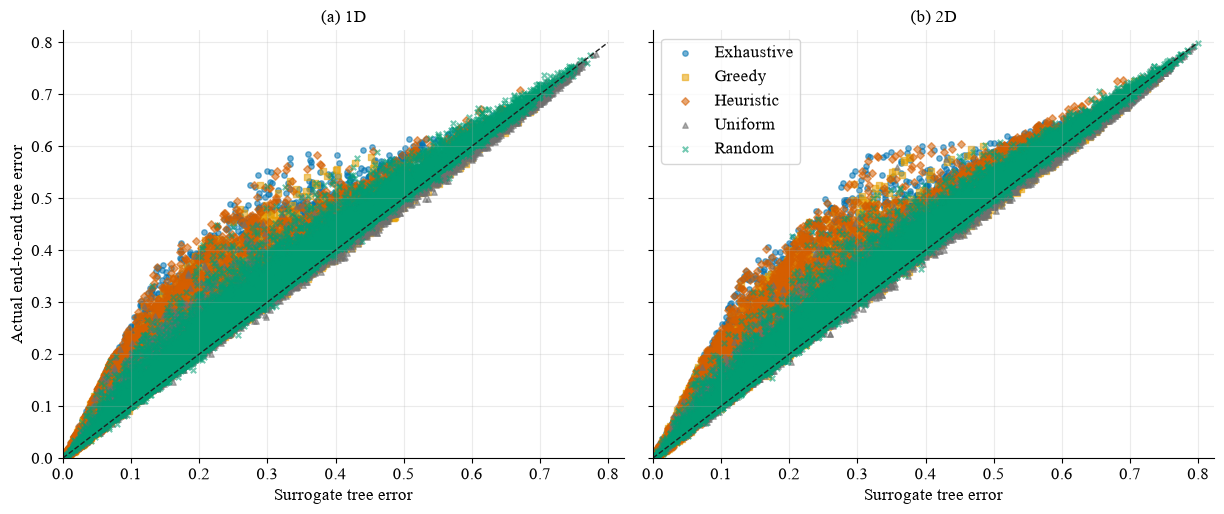

### Figure 2: Algorithm performance using actual error

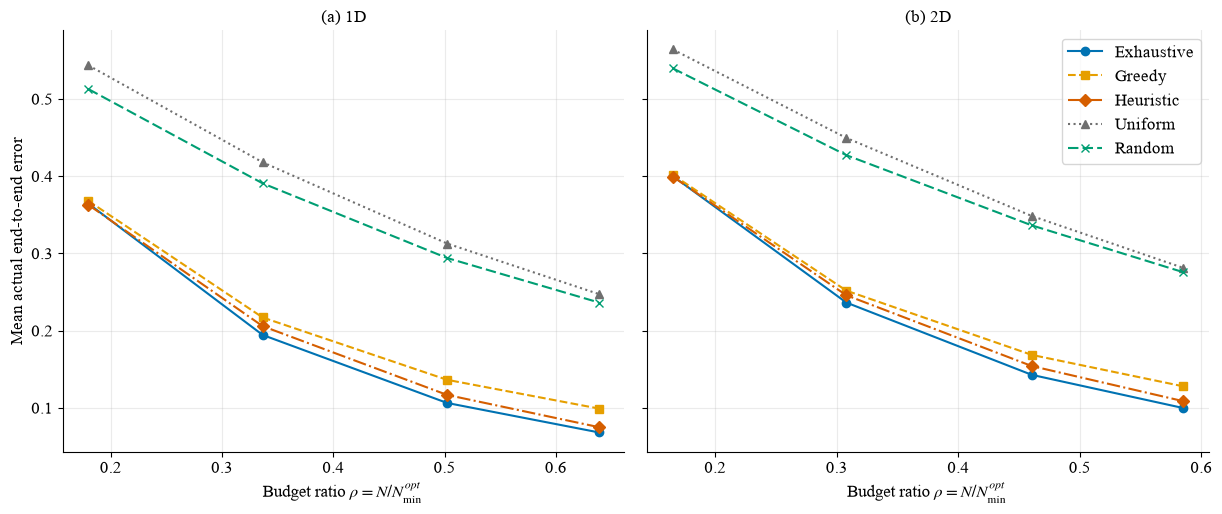

In [50]:
# Create, save, and display the two compact actual-error final figures inline.
for title, figure in actual_error_analysis.make_combined_actual_error_plots(
    compact_records_by_dataset,
    ACTUAL_RESULTS_ROOT,
    run_scope=COMPACT_RUN_SCOPE,
):
    display(Markdown(f"### {title}"))
    display(figure)
    plt.close(figure)


## Interpretation Summary

This section lists the figures and numerical summaries intended for the analysis and states the interpretation without overstating what the surrogate validation proves.


In [51]:
print("Final figures to include")
print("1. Figure 1: surrogate final error vs actual final error, with 1D and 2D panels and y=x.")
print("2. Figure 2: mean actual end-to-end error vs budget ratio, with 1D and 2D panels.")

print("\nAnalysis-number checklist")
print("- Bias and MAE by dimension and method: calibration of the surrogate.")
print("- Pearson/Spearman by dimension and method, plus pooled all-method values: ranking proxy strength.")
print("- Within-budget Pearson/Spearman: checks whether pooled correlation is driven only by budget trend.")
print("- Method-ranking agreement: how often surrogate-best is also actual-best.")
print("- Mean actual errors and Heuristic reduction vs Greedy: whether conclusions survive actual evaluation.")

print("\nInterpretation patterns")
print("- High correlation supports the surrogate as a ranking proxy, not as exact calibration.")
print("- Bias > 0 means the surrogate underestimates actual error on average; bias < 0 means it overestimates.")
print("- If within-budget correlations remain high, the relationship is not only due to the shared decrease with budget.")
print("- If Heuristic actual error is below Greedy, the algorithmic ranking survives actual-error reevaluation.")
print("- The Exhaustive curve is surrogate-exhaustive reevaluated with actual error, not an actual-error optimum.")

Final figures to include
1. Figure 1: surrogate final error vs actual final error, with 1D and 2D panels and y=x.
2. Figure 2: mean actual end-to-end error vs budget ratio, with 1D and 2D panels.

Analysis-number checklist
- Bias and MAE by dimension and method: calibration of the surrogate.
- Pearson/Spearman by dimension and method, plus pooled all-method values: ranking proxy strength.
- Within-budget Pearson/Spearman: checks whether pooled correlation is driven only by budget trend.
- Method-ranking agreement: how often surrogate-best is also actual-best.
- Mean actual errors and Heuristic reduction vs Greedy: whether conclusions survive actual evaluation.

Interpretation patterns
- High correlation supports the surrogate as a ranking proxy, not as exact calibration.
- Bias > 0 means the surrogate underestimates actual error on average; bias < 0 means it overestimates.
- If within-budget correlations remain high, the relationship is not only due to the shared decrease with budget.
